# 3. Fit material parameters at a fixed pose

Hold the tetrahedral bunny at a prescribed displacement $u$. Use a synthetic
nodal energy gradient as the observation and fit the material parameters
$p=(\lambda,\mu)$ that reproduce it.

The fitting chain is $p \longrightarrow g(u,p) \longrightarrow L$, where
$g=\partial E/\partial u$ is the positive energy gradient. We first build that
response, then check its Jacobian and compare two ways to differentiate the
same scalar loss. The synthetic observation includes all displacement DOFs.

In [20]:
from pathlib import Path
from time import perf_counter

import numpy as np
import torch
import matplotlib.pyplot as plt
%matplotlib inline
from torch.autograd import forward_ad
from litepgo import dof, energy, fem, mesh
from litepgo.torch import TorchVolumetricMaterial, response

torch.set_num_threads(1)
dtype = torch.float64

## Recreate the material and geometry

### Material at a quadrature point

`TorchNeoHookean` uses the density from lesson 2. `num_parameters = 2`
declares $\theta=(\lambda,\mu)$, in that order. `W` takes batches of $F$, $F_p$,
and $\theta$ and returns one density per point. It uses the elastic gradient
$F_e=FF_p^{-1}$ and scales by $\det F_p$ to give energy per original reference
volume. The adapter supplies the local stress and material derivatives from
this Torch function.

In [21]:
class TorchNeoHookean(TorchVolumetricMaterial):
    num_parameters = 2

    @staticmethod
    def W(F, Fp, theta):
        Fe = F @ torch.linalg.inv(Fp)
        lam, mu = theta.unbind(-1)
        log_J = torch.linalg.det(Fe).log()
        psi = (
            0.5 * mu * (Fe.square().sum((-2, -1)) - 3)
            - mu * log_J
            + 0.5 * lam * log_J.square()
        )
        W = torch.linalg.det(Fp) * psi
        return torch.where((lam >= 0) & (mu > 0), W, torch.full_like(W, float('nan')))

### Fix the reference geometry and the displacement

The VEG file provides the original vertex positions `X` and the tetrahedral
connectivity. `VertexDofMap(topology, 3)` assigns three displacement DOFs per
vertex. For each element, `mapping.gather(e, rest)` pulls out its reference
positions. `InterpolatedResponse[TetP1Basis]` uses them to map the reference
tetrahedron into the bunny. We use one centroid quadrature point per element.

The affine plastic field has a zero linear part and a constant identity
matrix, so $F_p=I$ throughout the mesh. We prescribe each vertex displacement
as $u_a=AX_a$ with the matrix `affine` below. The deformed position is
$(I+A)X_a$ and the resulting $F=I+A$ is constant across this mesh.
`.ravel()` packs $u$ into the same order as the 18,513 displacement DOFs.

In [22]:
asset_dir = next((folder for folder in (Path("."), Path("assets"), Path("../../assets"))
                  if (folder / "bunny-tet.veg").is_file()), Path("."))
bunny = mesh.read_veg(asset_dir / "bunny-tet.veg")
X, topology = bunny.positions, bunny.topology
mapping = dof.VertexDofMap(topology, 3)
rest = X.ravel()
geometry = [fem.InterpolatedResponse[fem.TetP1Basis](mapping.gather(e, rest))
            for e in range(topology.num_cells)]
Fp_field = energy.AffineResponse(np.zeros((9, 3)), np.eye(3).ravel(order='F'))
plastic = [Fp_field] * topology.num_cells
key = (TorchNeoHookean, fem.TetP1Basis, fem.TetCentroidQuadrature)

affine = np.array([
    [.08, .03, 0.],
    [0., -.02, .02],
    [.01, 0., .04],
])
u = (X @ affine.T).ravel()

## Make parameters the input

`VolumetricFemForceMaterialResponse` takes the pose `u` at construction. Once
that pose is set, `force.eval_value(p)` takes two material parameters and
returns the 18,513 components of the positive energy gradient
$g(u,p)=\partial E/\partial u$.

### One parameter pair for the whole bunny

`ConstantDofMap(topology, 2)` maps the two local material slots of every
tetrahedron to the same global slots `p[0]` and `p[1]`. When FEM evaluates
the density at an element's centroid, its local $\theta$ is therefore
the same pair $p=(\lambda,\mu)$. Changing $\mu$ from 3 to 3.01 changes the
value used by every tetrahedron, while the optimizer still updates just
one $\mu$.

### Assemble two columns from the local stress derivatives

The response requests `dPdtheta`, called `d2W_dF_dtheta` at the material
interface. Each centroid returns two $3\times3$ stress derivative matrices.
One gives the change in $P$ per unit change in $\lambda$, and the other
does the same for $\mu$.

From lesson 2, element $e$ contributes $V_eP_e\nabla_X N_a$ to the three
gradient entries at its vertex $a$. For parameter slot $j$, replace the
stress with its derivative to get the contribution to column $j$,

$$\frac{\partial g_a^{(e)}}{\partial p_j}
= V_e\frac{\partial P_e}{\partial\theta_j}\nabla_X N_a.$$

If two tetrahedra share a vertex, their $\mu$ contributions are added to
the same three displacement rows and the same global $\mu$ column. The
$\lambda$ contributions are assembled into the other column in the same
way. The result is $B=\partial g/\partial p$, with shape `(18513, 2)`.
Each row corresponds to one displacement DOF. The two columns describe
how its energy gradient changes when we vary $\lambda$ or $\mu$ at fixed `u`.

In [23]:
parameter_map = dof.ConstantDofMap(topology, 2)

def force_at(displacement):
    return fem.VolumetricFemForceMaterialResponse[key](
        parameter_map, mapping, geometry, displacement, plastic,
    )

force = force_at(u)

## Define the fitting loss

Generate the target nodal gradient using `truth = [2, 3]`. The trial response
uses the same geometry, $F_p$, and displacement $u$. Only the material
parameters vary. L-BFGS updates $q=\log p$, so the physical parameters
$p=\exp(q)$ stay positive.

We divide each discrepancy by `scale`, the root mean square of the target
gradient. For $N$ displacement DOFs, define the residual and loss as

$$r=\frac{g(u,\exp(q))-g_{\rm target}}{\mathrm{scale}},
\qquad L(q)=\frac{\|r\|_2^2}{2N}.$$

The normalization stays fixed throughout the fit.

In [24]:
truth = np.array([2., 3.])
target = torch.from_numpy(force.eval_value(truth).copy())
scale = target.square().mean().sqrt().item()
assert scale > 0
q_start = torch.tensor([1.2, 2.0], dtype=dtype).log()

def loss(q):
    predicted = response(force, q.exp())
    residual = (predicted - target) / scale
    return 0.5 * residual.square().mean()

initial_loss = loss(q_start).item()
print('response input/output dimensions:', q_start.numel(), target.numel())
print('initial loss:', initial_loss)

response input/output dimensions: 2 18513
initial loss: 0.0637311037394071


## Build the full Jacobian with forward mode

A Jacobian–vector product (JVP) returns $Bv$, the rate of change of all
18,513 nodal gradient entries along parameter direction $v$. The direction
$(1,0)$ selects the $\lambda$ column and $(0,1)$ selects the $\mu$ column.
Each call returns a whole column, so two JVPs give the full $B$.

`make_dual` sends the physical parameters `p` and the direction together.
The response bridge calls `force.eval_jvp`, and `unpack_dual` gives the
ordinary response $g$ and the tangent $Bv$. Stack the two tangents side
by side and compare every entry with `force.eval_jacobian`.

In [25]:
def value_and_jacobian(p):
    columns = []
    for direction in torch.eye(p.numel(), dtype=p.dtype):
        with forward_ad.dual_level():
            dual_p = forward_ad.make_dual(p, direction)
            nodal_gradient, tangent = forward_ad.unpack_dual(response(force, dual_p))
        columns.append(tangent)
    return nodal_gradient, torch.stack(columns, dim=1)

p_start = q_start.exp()
_, B = value_and_jacobian(p_start)
B_reference = force.eval_jacobian(p_start.numpy()).toarray()
assert B.shape == (target.numel(), p_start.numel())
np.testing.assert_allclose(B.numpy(), B_reference, rtol=1e-12, atol=1e-12)
print('B shape:', tuple(B.shape))
print(f'Max error versus eval_jacobian: {np.max(np.abs(B.numpy() - B_reference)):.2e}')

B shape: (18513, 2)
Max error versus eval_jacobian: 0.00e+00


## Check the scalar loss gradient

The optimizer needs $\nabla_q L$. The normalized residual gives
$\nabla_g L=r/(N\,\mathrm{scale})$. The remaining chain rule is

$$\nabla_p L=B^\mathsf{T}\nabla_g L,
\qquad \nabla_q L=p\odot\nabla_p L.$$

With the full Jacobian from the two JVPs, we apply those two operations
explicitly. With reverse mode, Torch sends $\nabla_g L$ to the response's
native VJP, which returns $B^\mathsf{T}\nabla_g L$. Torch then differentiates
$p=\exp(q)$. Check both gradients against each other and against central
differences of the complete loss in $q$.

In [26]:
def forward_loss_and_grad(q):
    p = q.detach().exp()
    predicted, B = value_and_jacobian(p)
    residual = (predicted - target) / scale
    value = 0.5 * residual.square().mean()
    grad_g = residual / (target.numel() * scale)
    grad_p = B.T @ grad_g
    return value, p * grad_p

q = q_start.clone().requires_grad_()
reverse_value = loss(q)
reverse_grad, = torch.autograd.grad(reverse_value, q)
forward_value, forward_grad = forward_loss_and_grad(q)

h = 1e-4
numerical = []
for delta in h * torch.eye(q_start.numel(), dtype=dtype):
    plus = loss(q_start + delta)
    minus = loss(q_start - delta)
    numerical.append((plus - minus) / (2 * h))
numerical_grad = torch.stack(numerical)

torch.testing.assert_close(forward_value, reverse_value)
torch.testing.assert_close(forward_grad, reverse_grad, rtol=1e-10, atol=1e-12)
torch.testing.assert_close(reverse_grad, numerical_grad, rtol=2e-4, atol=2e-6)
print('Reverse VJP:      ', reverse_grad.detach().numpy())
print('Forward Jacobian: ', forward_grad.numpy())
print('Finite difference:', numerical_grad.numpy())

Reverse VJP:       [-0.07729686 -0.15186194]
Forward Jacobian:  [-0.07729686 -0.15186194]
Finite difference: [-0.07729686 -0.15186194]


## Fit with the same L-BFGS loop

Both fits start from `q_start` and use the same line search and tolerances.
In the reverse closure, `backward()` populates `q.grad`. In the forward closure,
we set `q.grad` to the gradient computed from the two JVPs. L-BFGS can call
either closure multiple times during a line search.

In [27]:
def reverse_step(q):
    value = loss(q)
    value.backward()
    return value

def forward_step(q):
    value, gradient = forward_loss_and_grad(q)
    q.grad = gradient
    return value

def fit(gradient_step):
    q = q_start.clone().requires_grad_()
    history = []
    optimizer = torch.optim.LBFGS(
        [q], max_iter=25, tolerance_grad=1e-10,
        tolerance_change=1e-14, line_search_fn='strong_wolfe',
    )

    def closure():
        optimizer.zero_grad()
        value = gradient_step(q)
        history.append(value.item())
        return value

    start = perf_counter()
    optimizer.step(closure)
    elapsed = perf_counter() - start

    fitted = q.detach().exp().numpy()
    final_loss = loss(q.detach()).item()
    assert np.isfinite(final_loss) and final_loss < initial_loss * 1e-5
    np.testing.assert_allclose(fitted, truth, rtol=1e-3, atol=1e-3)
    return elapsed, history, fitted, final_loss

## Time the two optimization paths

Warm up with one full fit per method. Then alternate the run order and report
the median of three timed fits per method. Time the L-BFGS step, including all
line-search evaluations. Compare the closure counts and time per closure to
separate the number of evaluations from the cost of each one.

Reverse VJP: 2.856 s per fit, 238.0 ms per closure
  12 calls, loss 6.373e-02 → 4.194e-15, fitted [2.00000047 2.9999999 ]
Forward 2 JVPs: 5.463 s per fit, 455.3 ms per closure
  12 calls, loss 6.373e-02 → 4.194e-15, fitted [2.00000047 2.9999999 ]
Forward / reverse fit time: 1.91×


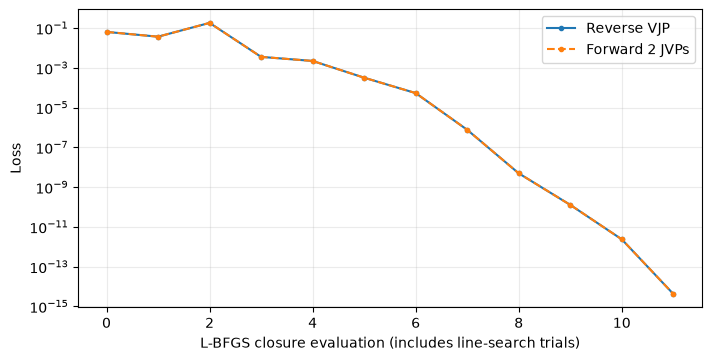

In [28]:
methods = (('Reverse VJP', reverse_step), ('Forward 2 JVPs', forward_step))
runs = {label: [] for label, _ in methods}
for repeat in range(4):
    order = methods if repeat % 2 == 0 else methods[::-1]
    for label, step in order:
        result = fit(step)
        if repeat > 0:
            runs[label].append(result)

fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
medians = {}
for (label, samples), style in zip(runs.items(), ('-', '--')):
    median_seconds = np.median([elapsed for elapsed, _, _, _ in samples])
    median_ms_per_call = np.median([
        1000 * elapsed / len(history) for elapsed, history, _, _ in samples
    ])
    medians[label] = median_seconds
    _, history, fitted, final_loss = samples[-1]
    print(f'{label}: {median_seconds:.3f} s per fit, {median_ms_per_call:.1f} ms per closure')
    print(f'  {len(history)} calls, loss {initial_loss:.3e} → {final_loss:.3e}, fitted {fitted}')
    ax.semilogy(np.maximum(history, 1e-18), style, marker='.', label=label)

ratio = medians['Forward 2 JVPs'] / medians['Reverse VJP']
print(f'Forward / reverse fit time: {ratio:.2f}×')
ax.set(xlabel='L-BFGS closure evaluation (includes line-search trials)', ylabel='Loss')
ax.legend()
ax.grid(alpha=0.25)
plt.show()

### Why the two-JVP fit takes longer

Look at the work inside one closure. A dual call to `response(force, dual_p)`
first runs `eval_value`. This evaluates the material stress $P$ and assembles
the ordinary nodal gradient $g$. It then runs `eval_jvp`. The native JVP builds
the local Jacobians $B_e$: the Torch material recomputes $P$ and evaluates
`dPdtheta`, and native FEM maps those derivatives to the element's displacement
rows. This path builds both parameter columns of each local block. The JVP then
multiplies each block by the supplied direction and adds the results to the
global displacement rows.

For the second direction, `value_and_jacobian` repeats both calls at the
same $p$. The first call's $g$ and local Jacobians are not reused. The sampled
$F$, $F_p$, and geometry are already stored by the fixed-pose response.

| Work per closure | Reverse | Forward with full $B$ |
| --- | ---: | ---: |
| Value evaluation and assembly of $g$ | 1 | 2 |
| Material mixed derivatives and local Jacobian build | 1 | 2 |
| Stress evaluations per material point across those calls | 2 | 4 |
| Jacobian product | One $B^\mathsf{T}\nabla_g L$ | Two $Bv$ columns |

The reverse closure already has the loss weights $\nabla_g L$. Its VJP
multiplies each local block by the corresponding nodal weights, then sums
the results into the two shared parameter slots. It gets both loss gradient
components in one derivative call. When both fits take the same number of
closures, the repeated value and derivative work explains why the forward
implementation takes close to twice as long here. The timing includes the
whole optimizer step and varies with the machine and implementation.

## Try it

1. Set the off-diagonal entries of `affine` to zero while keeping the
   diagonal entries. Rebuild `force` for this pose and compare the two columns
   of `force.eval_jacobian(truth)` with those at the original pose.
2. Prescribe a uniform 10% stretch in all three directions, so $F=1.10I$.
   Rebuild `force` for this pose. Are the two columns of $B$ independent?
   Can you find a second pair of positive material parameters that gives
   the same nodal gradient $g$ as `truth`?

### 1. Remove shear and compare conditioning

The inner `np.diag(affine)` takes the three diagonal entries. The outer
`np.diag` puts them into a new diagonal matrix with zero off-diagonal
entries. Rebuild the fixed-pose response from this displacement and
evaluate its Jacobian.

The condition number compares the largest and smallest singular values.
A large ratio would mean that some parameter direction has a much weaker
effect on $g$ than another. The diagonal stretches still change the volume
and the shape here, so the two condition numbers are close.

In [29]:
no_shear = np.diag(np.diag(affine))
force_no_shear = force_at((X @ no_shear.T).ravel())
B_original = force.eval_jacobian(truth).toarray()
B_no_shear = force_no_shear.eval_jacobian(truth).toarray()
print(f'Condition number, original: {np.linalg.cond(B_original):.2f}')
print(f'Condition number, no shear: {np.linalg.cond(B_no_shear):.2f}')

Condition number, original: 1.85
Condition number, no shear: 1.88


### 2. Apply uniform stretch and check proportionality

The displacement $(s-1)X$ puts every vertex at $sX$ and gives $F=sI$.
Use $s=1.10$ and build a response for that pose.

With $F_p=I$, the stress splits into a $\lambda$ term and a $\mu$ term,

$$P = \lambda \log J\,F^{-\mathsf{T}} + \mu(F-F^{-\mathsf{T}}),
\qquad J=\det F.$$

For $F=sI$, we have $J=s^3$ and $F^{-\mathsf{T}}=I/s$. Both parameter terms
are now multiples of the same matrix,

$$P = \left(\frac{3\log s}{s}\,\lambda
           + (s-s^{-1})\,\mu\right)I.$$

When FEM passes that stress back to the nodes, the element contribution at
vertex $a$ is $V_e P\nabla_X N_a$. With $P=cI$, each contribution is multiplied
by the same scalar $c$. The geometry determines the pattern of all nodal
gradient entries, and the material parameters determine its amplitude.
Both parameters affect $g$, but they produce the same pattern. Thus the
$\lambda$ column is the $\mu$ column times $3\log(s)/(s^2-1)$.

`B_uniform.T` exposes the two parameter columns as separate vectors.
Check the proportionality entry by entry. The two singular values give
another view of the same result. The smaller one is near zero, so there
is only one independent response direction.

In [30]:
stretch = 1.10
uniform_u = ((stretch - 1) * X).ravel()
force_uniform = force_at(uniform_u)
B_uniform = force_uniform.eval_jacobian(truth).toarray()

column_ratio = 3 * np.log(stretch) / (stretch**2 - 1)
lambda_column, mu_column = B_uniform.T
assert np.linalg.norm(mu_column) > 1e-12
np.testing.assert_allclose(lambda_column, column_ratio * mu_column, rtol=1e-10, atol=1e-12)
print(f'Uniform stretch: lambda column = {column_ratio:.6f} × mu column')
print('Singular values:', np.linalg.svd(B_uniform, compute_uv=False))

Uniform stretch: lambda column = 1.361574 × mu column
Singular values: [3.44462279e-04 9.23363238e-19]


### 3. Compare two parameter pairs at the same pose

Increasing $\lambda$ by 1 adds the $\lambda$ column to the predicted $g$.
Decreasing $\mu$ by `column_ratio` subtracts the same change. This gives
the alternative pair while keeping the uniform stretch fixed.

Call `eval_value` once per pair and compare all 18,513 entries. Treating the
reference response as the target, the normalized loss is half the squared
relative difference. A near-zero loss here leaves the parameters ambiguous.

In [31]:
alternative = truth + np.array([1., -column_ratio])
g_truth = force_uniform.eval_value(truth)
g_alternative = force_uniform.eval_value(alternative)
np.testing.assert_allclose(g_alternative, g_truth, rtol=1e-10, atol=1e-12)
difference = g_alternative - g_truth
relative_error = np.linalg.norm(difference) / np.linalg.norm(g_truth)
print('Parameter pairs:', truth, 'and', alternative)
print(f'Max nodal gradient difference: {np.max(np.abs(difference)):.2e}')
print(f'Normalized loss at the alternative pair: {0.5 * relative_error**2:.2e}')

Parameter pairs: [2. 3.] and [3.       1.638426]
Max nodal gradient difference: 1.22e-19
Normalized loss at the alternative pair: 8.11e-31


### See the loss surface

Both panels use the same reference parameters. Each pose has its own target
nodal gradient generated at those parameters. At fixed $F$ and $F_p$, the
Neo-Hookean nodal gradient is linear in $p$. Thus the exact discrepancy is
$B(p-p_{\rm true})$. We can evaluate the normalized loss across a parameter
grid using the $2\times2$ matrix $B^\mathsf{T}B$.

In the original pose, the contours surround one minimum. In the uniform
stretch, they form parallel bands. The dashed line shows the parameter
pairs that give the same response as the reference pair. The alternative
pair lies on that line. Values below $10^{-6}$ share the darkest color.

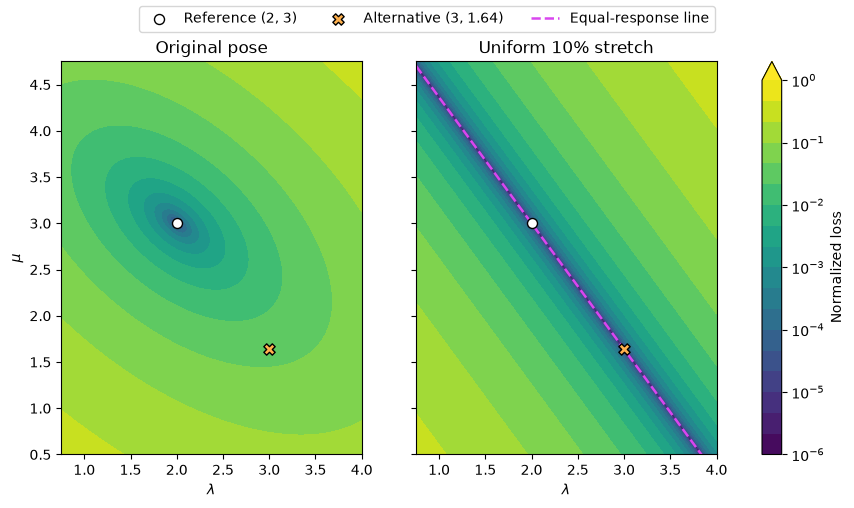

In [32]:
from matplotlib.colors import LogNorm

lambda_values = np.linspace(.75, 4., 241)
mu_values = np.linspace(.5, 4.75, 241)
lambda_grid, mu_grid = np.meshgrid(lambda_values, mu_values)
delta_p = np.stack((lambda_grid, mu_grid), axis=-1) - truth
levels = np.geomspace(1e-6, 1, 19)

np.testing.assert_allclose(B_original @ truth, target.numpy(), atol=1e-12)
np.testing.assert_allclose(B_uniform @ alternative, g_alternative, atol=1e-12)

fig, axes = plt.subplots(1, 2, figsize=(8.7, 5), sharey=True, constrained_layout=True)
poses = (
    ('Original pose', B_original, target.numpy()),
    ('Uniform 10% stretch', B_uniform, g_truth),
)
for ax, (title, jacobian, observation) in zip(axes, poses):
    gram = (jacobian.T @ jacobian) / np.dot(observation, observation)
    loss_grid = 0.5 * ((delta_p @ gram) * delta_p).sum(axis=-1)
    contours = ax.contourf(
        lambda_grid, mu_grid, np.maximum(loss_grid, levels[0]),
        levels=levels, norm=LogNorm(), cmap='viridis', extend='max',
    )
    ax.scatter(*truth, color='white', edgecolor='black', s=52,
               zorder=4, label=f'Reference ({truth[0]:g}, {truth[1]:g})')
    ax.scatter(*alternative, color='#ffb14e', edgecolor='black', marker='X',
               s=66, zorder=4, label=f'Alternative ({alternative[0]:.0f}, {alternative[1]:.2f})')
    ax.set(title=title, xlabel=r'$\lambda$', aspect='equal',
           xlim=(lambda_values[0], lambda_values[-1]), ylim=(mu_values[0], mu_values[-1]))

equal_mu = truth[1] - column_ratio * (lambda_values - truth[0])
axes[1].plot(lambda_values, equal_mu, '--', color='#d946ef', linewidth=1.8,
             label='Equal-response line')
axes[0].set_ylabel(r'$\mu$')
fig.colorbar(contours, ax=axes, label='Normalized loss', ticks=np.geomspace(1e-6, 1, 7))
fig.legend(*axes[1].get_legend_handles_labels(), loc='outside upper center', ncol=3)
plt.show()

**Checkpoint** You can fit explicit material parameters through a native response.
Next, allow the pose itself to change when the parameters change.